In [1]:
from datascience import *
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)

from urllib.request import urlopen 
import re
def read_url(url): 
    return re.sub('\\s+', ' ', urlopen(url).read().decode())

# Week 2 - Notebook 1: 2.1

## 2.1: 5-Number Summary, Range, IQR, and Outliers

### Calculating the 5-number Summary Using Numpy ###


In [2]:
data = [1, 2, 2, 3, 4, 5, 5, 6, 7, 8, 9, 10]

minimum = np.min(data)
q1 = np.percentile(data, 25)
median = np.median(data)
q3 = np.percentile(data, 75)
maximum = np.max(data)

print(f"Minimum: {minimum}")
print(f"Q1 (25th percentile): {q1}")
print(f"Median (50th percentile): {median}")
print(f"Q3 (75th percentile): {q3}")
print(f"Maximum: {maximum}")

# Alternatively, you can use np.percentile to get all at once:
five_num_summary = np.percentile(data, [0, 25, 50, 75, 100])
print(f"\nFive-number summary (array): {five_num_summary}")

Minimum: 1
Q1 (25th percentile): 2.75
Median (50th percentile): 5.0
Q3 (75th percentile): 7.25
Maximum: 10

Five-number summary (array): [  1.     2.75   5.     7.25  10.  ]


### Calculating the 5-number Summary Using Numpy Midpoint Method ###

In [3]:
minimum = np.min(data)
q1 = np.percentile(data, 25, method = 'midpoint')
median = np.median(data)
q3 = np.percentile(data, 75, method = 'midpoint')
maximum = np.max(data)

print(f"Minimum: {minimum}")
print(f"Q1 (25th percentile): {q1}")
print(f"Median (50th percentile): {median}")
print(f"Q3 (75th percentile): {q3}")
print(f"Maximum: {maximum}")

# Alternatively, you can use np.percentile to get all at once:
five_num_summary = np.percentile(data, [0, 25, 50, 75, 100], method='midpoint')
print(f"\nFive-number summary (array): {five_num_summary}")

Minimum: 1
Q1 (25th percentile): 2.5
Median (50th percentile): 5.0
Q3 (75th percentile): 7.5
Maximum: 10

Five-number summary (array): [  1.    2.5   5.    7.5  10. ]


### Create a funtion for the 5-Number Summary ###
Note: you will need to recreate this function in any notebook you create if you plan to use it.

In [4]:
def Summary_5(data):
    minimum = np.min(data)
    q1 = np.percentile(data, 25, method = 'midpoint')
    median = np.median(data)
    q3 = np.percentile(data, 75, method = 'midpoint')
    maximum = np.max(data)

    print(f"Minimum: {minimum}")
    print(f"Q1 (25th percentile): {q1}")
    print(f"Median (50th percentile): {median}")
    print(f"Q3 (75th percentile): {q3}")
    print(f"Maximum: {maximum}")
    return minimum, q1, median, q3, maximum


### Finding the Range and IQR

Range: The spread of the data. Max - Min.

IQR(Interquartile Range) The spread of the middle 50% of the data. Q3 - Q1

Find the Range and the IQR manually from the 5-number summary above. 

In [5]:
10 - 1

9

In [6]:
7.5 - 2.5

5.0

### Create a function that will give both the range and the IQR of any data set.
Note: you will need to recreate this function in any notebook you create if you plant to use it.

In [7]:
def Summary_ranges(data):
    minimum, q1, median, q3, maximum = Summary_5(data)
    range = maximum - minimum
    IQR = q3 - q1

    print(f"Range = {range}")
    print(f"IQR = {IQR}")
    return range, IQR, q1, q3

In [8]:
Summary_ranges(data)

Minimum: 1
Q1 (25th percentile): 2.5
Median (50th percentile): 5.0
Q3 (75th percentile): 7.5
Maximum: 10
Range = 9
IQR = 5.0


(9, 5.0, 2.5, 7.5)

### Finding Outliers
Outliers: values that are outside of the expected range. 
    
To find any outlier, first we have to find the highest and lowest expected values. 
* Lowest expected value = Lower fence = Q1 - IQR(1.5)
* Highest expected value = Upper fence = Q3 + IQR(1.5)

Once we have the fences, if there is any number in the data above the upper fence or below the lower fence, those values would be outliers. 

Calculate the fences for the above data manually, then create a function that builds in the fences to the Summary.

In [9]:
Lower = 2.5 - 4.5*1.5
Upper = 7.5 + 4.5*1.5

print(f"Lower Fence = {Lower}")
print(f"Upper Fence = {Upper}")

Lower Fence = -4.25
Upper Fence = 14.25


#### Are there any outliers in this data set?
We will need to look at the data since the method in Python to identlfy outliers is beyond the scope of this class.

No. There are no outliers. 


In [10]:
def Summary_outliers(data):
    range, IQR, q1, q3 = Summary_ranges(data)
    Lower = q1 - IQR*1.5
    Upper = q3 + IQR*1.5

    print(f"Lower Fence = {Lower}")
    print(f"Upper Fence = {Upper}")

In [11]:
Summary_outliers(data)

Minimum: 1
Q1 (25th percentile): 2.5
Median (50th percentile): 5.0
Q3 (75th percentile): 7.5
Maximum: 10
Range = 9
IQR = 5.0
Lower Fence = -5.0
Upper Fence = 15.0


### Display the data graphically in a BoxPlot

A boxplot graph displays the 5 number summay with a visual representation. 

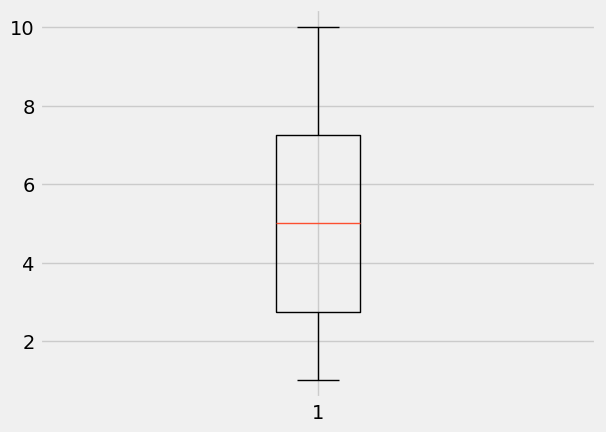

In [12]:
plots.boxplot(data);


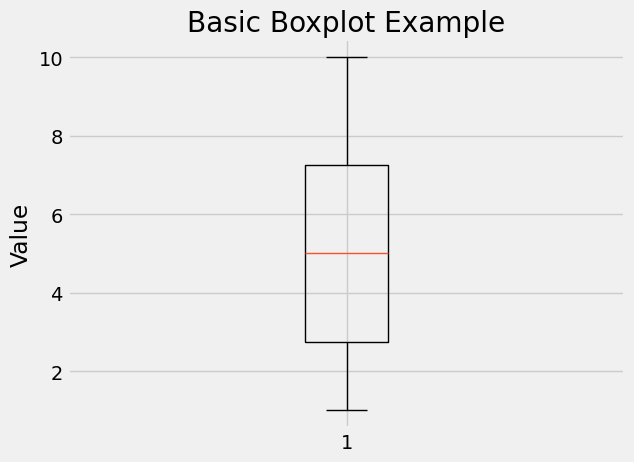

In [13]:
plots.boxplot(data);
# Add title and labels 
plots.title("Basic Boxplot Example");
plots.ylabel("Value");
#plots.ylim(0,12);
#plots.yticks(np.arange(0, 12, 1)); 


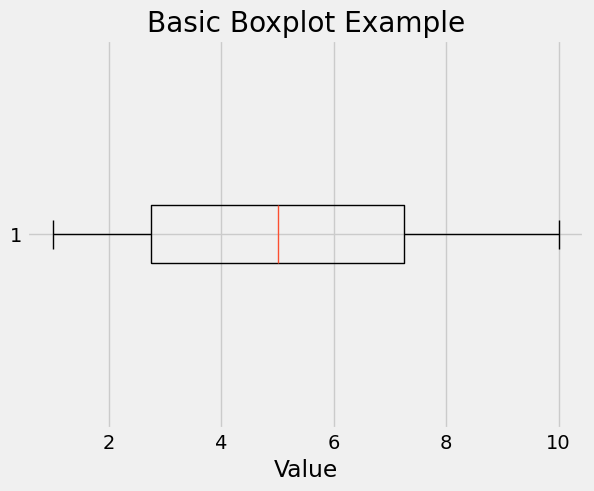

In [14]:
plots.boxplot(data, orientation = 'horizontal');
# Add title and labels 
plots.title("Basic Boxplot Example");
plots.xlabel("Value");
#plots.xlim(0,12);
#plots.xticks(np.arange(0, 12, 1)); 


***QUESTION: Which chart best displays the data, which optional commands did you incorporate and why?***


## Analyzing Real Data 

### Calculating the 5-Number Summary from a CSV ###

#### Import Data 

***Run the next cell then describe the table:***
 * Content: NBA players, their position, team, salary and season
 * Variables:
 * Units for variables:
 * Quantitative Variables:
 * Qualitative Variables:
 * Other notable information:(how many records, etc)

In [16]:
nba = Table.read_table('nba_salaries.csv')
nba.show(3)

rank,name,position,team,salary,season
1,Shaquille O'Neal,C,Los Angeles Lakers,17142000,2000
2,Kevin Garnett,PF,Minnesota Timberwolves,16806000,2000
3,Alonzo Mourning,C,Miami Heat,15004000,2000


***QUESTION: What are the seasons represented in this data?***  
Use the sort command to determine the range of the years in this table.  
Add that information to the description above.

In [18]:
nba.sort('season', descending = True)

rank,name,position,team,salary,season
1,Stephen Curry,PG,Golden State Warriors,40231758,2020
2,Chris Paul,PG,Oklahoma City Thunder,38506482,2020
3,Russell Westbrook,PG,Houston Rockets,38506482,2020
4,John Wall,PG,Washington Wizards,38199000,2020
5,Kevin Durant,SF,Brooklyn Nets,38199000,2020
6,James Harden,SG,Houston Rockets,38199000,2020
7,LeBron James,SF,Los Angeles Lakers,37436858,2020
8,Kyle Lowry,PG,Toronto Raptors,34996296,2020
9,Blake Griffin,PF,Detroit Pistons,34449964,2020
10,Tobias Harris,SF,Philadelphia 76ers,32742000,2020


### Let's find the 5-Number Summary of the Salary ###

In [17]:
data1 = nba.column('salary')

In [18]:
Summary_5(data1)

Minimum: 2692
Q1 (25th percentile): 915243.0
Median (50th percentile): 2351329.5
Q3 (75th percentile): 5823655.0
Maximum: 40231758


(2692, 915243.0, 2351329.5, 5823655.0, 40231758)

#### How would you interpret these values knowing that the context is the salary of NBA players between 2000 and 2020? 

* Somebody was paid a salary of \$2692 as the lowest.
* The maximum salary for these players was \$40,231,758
* The median salary for players is \$2,351,329.50 which means 50% of the players make more than this and 50% of the players make less than this.
* 25% of the players make \$915,243.00 or less
* 25% of the players make \$5,823,655.00 or more

#### Does the fact that the years vary from 2000 and 2020 have any affect on this information? 

Yes cost of living changes a lot over 20 years.

In [19]:
#### Who and when was the lowest paid person?
nba.where('salary',(min(nba.column('salary'))))

rank,name,position,team,salary,season
481,Tony Gaffney,SF,Memphis Grizzlies,2692,2010
482,Oliver Lafayette,G,Boston Celtics,2692,2010


#### Who and when was the highest paid person?

In [20]:
nba.where('salary',(max(nba.column('salary'))))

rank,name,position,team,salary,season
1,Stephen Curry,PG,Golden State Warriors,40231758,2020


#### What could be done to get a more accurate understaning of salary comparisons?

Look at one year at a time or look at a smaller range of years. Take out the partial season players.


### Find the Range and IQR of the NBA Salaries

In [21]:
Summary_ranges(data1)

Minimum: 2692
Q1 (25th percentile): 915243.0
Median (50th percentile): 2351329.5
Q3 (75th percentile): 5823655.0
Maximum: 40231758
Range = 40229066
IQR = 4908412.0


(40229066, 4908412.0, 915243.0, 5823655.0)

#### What do these numbers mean knowing that the context is the salary of NBA players between 2000 and 2020?
##### Focus on the Range and IQR.

* The difference between the highest and lowest salary is \$40,229,066.
* The middle 50% of the salary range is \$4,908,412.00

### Are there any outliers in the data?

In [22]:
Summary_outliers(data1)

Minimum: 2692
Q1 (25th percentile): 915243.0
Median (50th percentile): 2351329.5
Q3 (75th percentile): 5823655.0
Maximum: 40231758
Range = 40229066
IQR = 4908412.0
Lower Fence = -6447375.0
Upper Fence = 13186273.0


#### Can there be outliers?
Yes there can be high outliers, but not low ones. 

#### If yes, determine which players are outliers and how many, if there are any.

In [23]:
nba.sort('salary', descending = False)

rank,name,position,team,salary,season
481,Tony Gaffney,SF,Memphis Grizzlies,2692,2010
482,Oliver Lafayette,G,Boston Celtics,2692,2010
490,Linton Johnson,PF,Toronto Raptors,4533,2008
491,Billy Thomas,SG,New Jersey Nets,4533,2008
597,Amile Jefferson,PF,Orlando Magic,4608,2018
598,Aaron Jackson,F,Houston Rockets,4608,2018
502,Theo Pinson,SG,Brooklyn Nets,4737,2019
503,Kendrick Nunn,SG,Miami Heat,4737,2019
480,Greg Stiemsma,C,Portland Trail Blazers,5383,2010
594,Dahntay Jones,SG,Cleveland Cavaliers,5767,2017


In [24]:
nba_fullseason = nba.where('salary', are.above(100000))
nba_fullseason.show(5)


rank,name,position,team,salary,season
1,Shaquille O'Neal,C,Los Angeles Lakers,17142000,2000
2,Kevin Garnett,PF,Minnesota Timberwolves,16806000,2000
3,Alonzo Mourning,C,Miami Heat,15004000,2000
4,Juwan Howard,PF,Washington Wizards,15000000,2000
5,Scottie Pippen,SF,Portland Trail Blazers,14795000,2000


In [25]:
nba_partseason = nba.where('salary', are.below_or_equal_to(100000))
nba_partseason

rank,name,position,team,salary,season
365,Doug Overton,PG,New Jersey Nets,90000,2001
366,Sean Colson,G,Houston Rockets,83000,2001
367,David Vanterpool,G,Washington Wizards,80000,2001
368,Steve Goodrich,F,Chicago Bulls,37000,2001
369,Eddie Gill,PG,New Jersey Nets,34000,2001
370,Chris Garner,G,Golden State Warriors,32000,2001
371,Scott Burrell,G,Charlotte Hornets,29000,2001
372,Dan McClintock,C,Denver Nuggets,26000,2001
373,Raja Bell,SG,Philadelphia 76ers,24000,2001
374,Jamel Thomas,F,New Jersey Nets,24000,2001


In [26]:
nba.where('salary', are.above(13186273.0)).num_rows

764

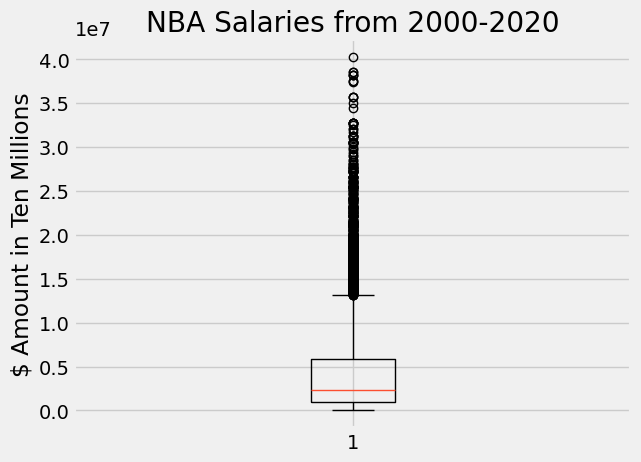

In [28]:
plots.boxplot(data1);
# Add title and labels 
plots.title("NBA Salaries from 2000-2020");
plots.ylabel("$ Amount in Ten Millions");


#### What observations could be made from these results?


#### What are some other questions that come up or answers that could be found with this data?